In [1]:
import sys, os; sys.path.insert(0, os.path.join(os.path.dirname(os.path.abspath('')), 'Utilities'))
import numpy as np
import matplotlib.pyplot as plt
import spiderman as sp
import batman
import hyperillumination_utils as hi
import hyperillumination_phasecurve_utils as hipc
import kepler_utils as k 
import batman_utils

looking for spidermanrc file at ~/.spidermanrc
no spidermanrc file detected


In [2]:
# Data from K2-141b (Malavolta et al. 2018, Barragán et al. 2018)
period=0.2803                               #orbital period [days]
rp = 0.0204                                 #planet radius [stellar radii / rs]
rs = 0.68                                   #stellar radius [solar radii]
a_AU = 0.007                                #semi-major axis [AU]   
a = k.AU_to_RS(a_AU, rs)                    #semi-major axis [stellar radii] 
incl = 86.3                                 #orbital inclination [degrees]
ecc = 0.                                    #eccentricity
w = 90.                                     #longitude of periastron [degrees] 
fp = 142e-6                                 #planet-to-star flux ratio / occultation depth Fp/Fs(alpha=0) (integrated day-side flux) - from Zieba 2022, using Spitzer’s IRAC Channel 2 at 4.5 µm
T_eff = 4570                                # stellar effective temperature [K]

u = [0.1, 0.3]                              # Stellar limb darkening coefficients [u1, u2] (placeholders, not from K2-141 data, will be set by theoretical stellar atmosphere models)

Ag = 0.28                                   # Geometric albedo from Zieba 2022, using Spitzer’s IRAC Channel 2 at 4.5 µm
A_B = 3/2*Ag                                # Assuming Lambertian reflectance. PROBABLY UNPHYSICAL!

In [3]:
# Wavelength ranges of various instruments in um. These are only effective ranges, used for approximate tophat filters.
effective_lambda_ranges = {
    "MIRI/F1280W": [11.6, 14.0], # MIRI imaging TSO, F1280W. Below CO₂ band, can check CO₂ atmosphere (combined with F1500W)
    "MIRI/F1500W": [13.5, 16.6], # MIRI imaging TSO, F1500W. Used on Trappist (15µm CO₂ band), Long wavelengths for cold nightside
    "MIRI/F1800W": [16.5, 19.5], # MIRI imaging TSO, F1800W. MIRI's thermal background climbs steeply past ~15 µm
    "MIRI/LRS": [5.0, 10.5], # Suggested by Sebastian, LRS runs to ~12 µm but red end trimmed (throughput drops)
    "Spitzer/IRAC": [4.0, 5.0] # ~Spitzer IRAC channel 2 (4.5 um), to compare with the measured occultation depth fp = 142 ppm (Zieba 2022)
}

In [4]:
# Wavelength range to be used
lambda_range = 1e-6*np.array(effective_lambda_ranges["Spitzer/IRAC"]) # wavelength range of detector [m]

## Thermal Phasecurve from Custom Spiderman brightness map (Hyperillumination)

### Build and verify the (lo, la, T) grid from `insolation_kopal`

In [5]:
lo, la, temp_grid = hipc.custom_temperature_grid(rp, 1, a, T_eff, insolation_model = "kopal")

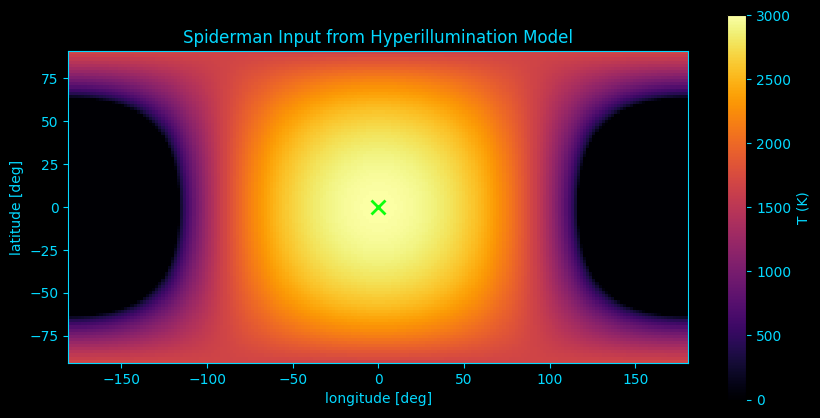

In [6]:
bg, tc = "black", "#04d9ff"   # same dark theme as plot_insolmap(..., theme='black')

fig, ax = plt.subplots(figsize=(10, 5), facecolor=bg)
im = ax.pcolormesh(lo, la, temp_grid, cmap=plt.cm.inferno, shading="auto")   # same colormap as plot_insolmap
ax.plot(0, 0, "x", color="#0cff0c", ms=10, mew=2)   # substellar point, same marker convention as spiderman's plot_square
ax.set_aspect("equal")
ax.set_facecolor(bg)
ax.set_xlabel("longitude [deg]", color=tc)
ax.set_ylabel("latitude [deg]", color=tc)
ax.tick_params(colors=tc)
for spine in ax.spines.values():
    spine.set_color(tc)

cbar = fig.colorbar(im, ax=ax)
cbar.ax.tick_params(colors=tc)
cbar.set_label("T (K)", color=tc)

ax.set_title("Spiderman Input from Hyperillumination Model", color=tc)
plt.show()

### SPIDERMAN phase curve from the custom brightness map (`direct_T`)

In [7]:
t_kopal, thermal_phasecurve_kopal, thermal_fp_kopal, spider_params_kopal = hipc.thermal_PhaseCurve(period, incl, ecc, w, rp, 1, a, T_eff, rs, lambda_range, u=u, insolation_model="kopal")
t_naive, thermal_phasecurve_naive, thermal_fp_naive, spider_params_naive = hipc.thermal_PhaseCurve(period, incl, ecc, w, rp, 1, a, T_eff, rs, lambda_range, u=u, insolation_model="naive")

no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation


#### Brightness Maps

/opt/anaconda3/envs/PhaseCurves/lib/python3.11/site-packages/spiderman/plot.py:133: UserWarning: Adding colorbar to a different Figure <Figure size 640x480 with 1 Axes> than <Figure size 924.855x800 with 5 Axes> which fig.colorbar is called on.
  cbar = plt.colorbar(mycax, cax=cbar_ax)


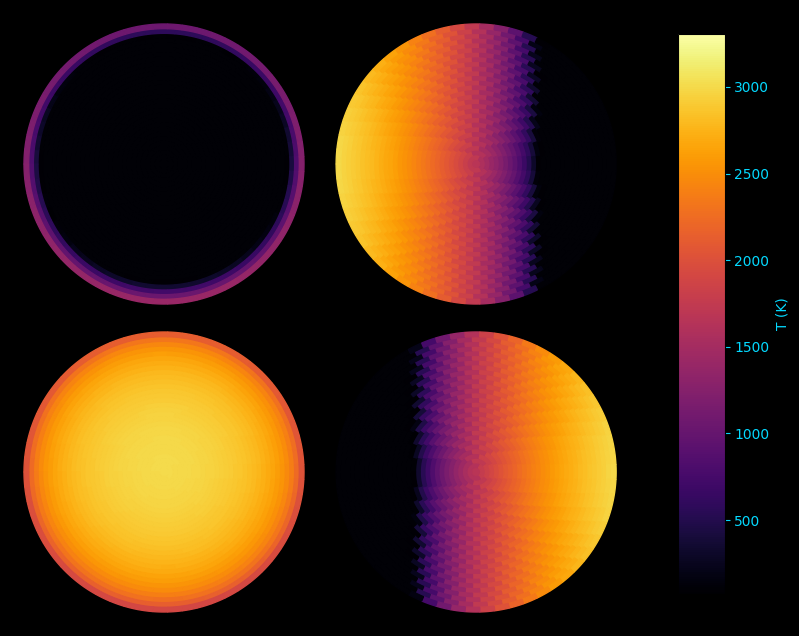

In [8]:
spider_params_kopal.plot_quad(temp_map=True,theme='black')
plt.show()

# phase = 0.25
# spider_params_kopal.plot_planet(phase,use_phase=True,temp_map=True, theme='black')
# plt.show()

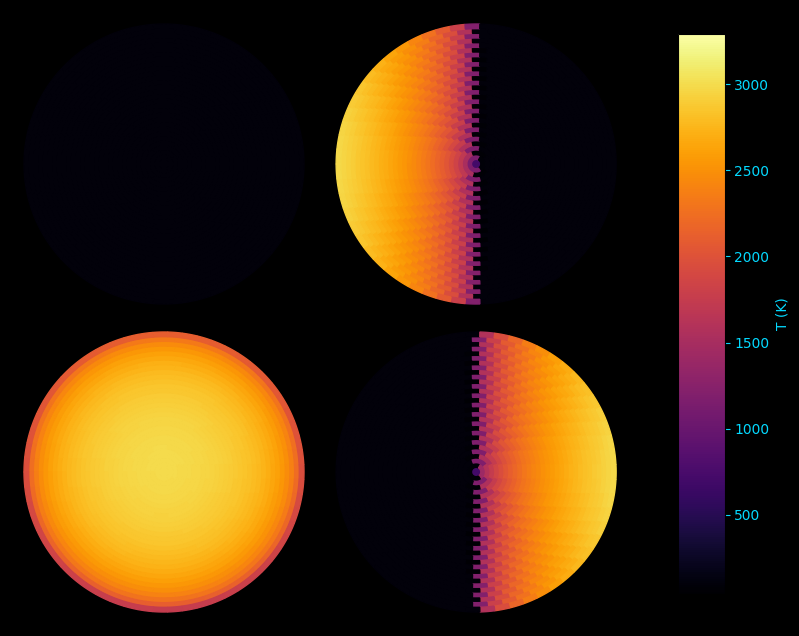

In [9]:
spider_params_naive.plot_quad(temp_map=True,theme='black')
plt.show()

# phase = 0.25
# phase_curve_naive.plot_planet(phase,use_phase=True,temp_map=True, theme='black')
# plt.show()

Slight asymmetry at phase=0 caused by incl = 86.3.

#### Phase Curve

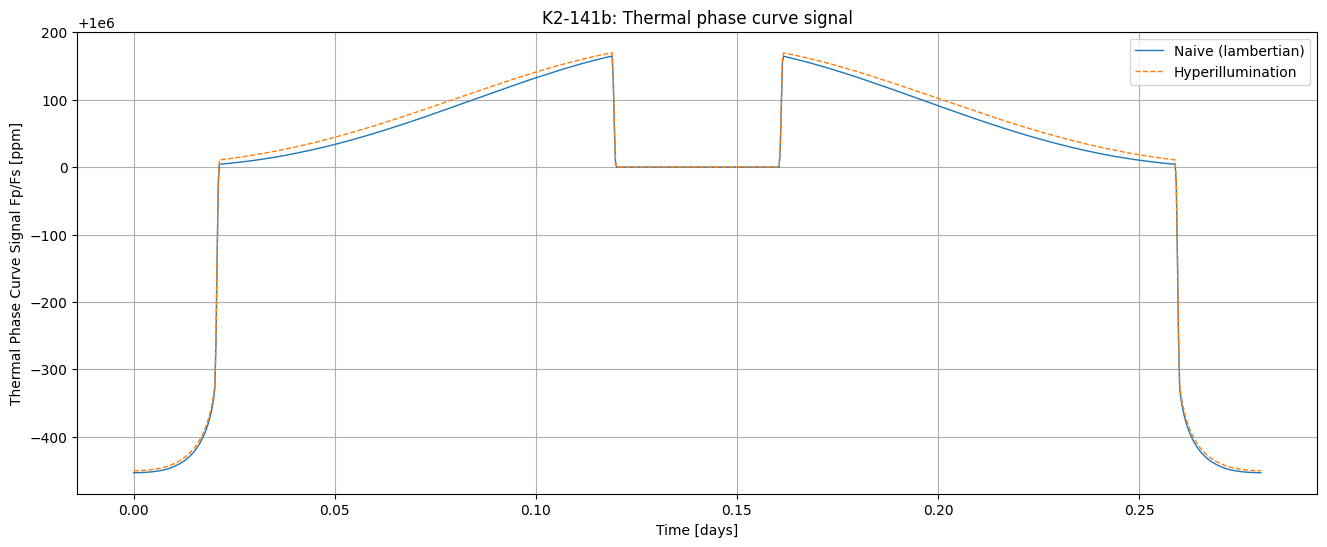

Occultation depth with Hyperillumination: 182.0 ppm   (measured: fp = 142 ppm at 4.5 um)
Occultation depth without Hyperillumination: 180.9 ppm   (measured: fp = 142 ppm at 4.5 um)


In [10]:
plt.figure(figsize=(16, 6))
plt.plot(t_naive, thermal_phasecurve_naive*1e6, linewidth=1, label="Naive (lambertian)")
plt.plot(t_kopal, thermal_phasecurve_kopal*1e6, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Thermal Phase Curve Signal Fp/Fs [ppm]")
plt.title("K2-141b: Thermal phase curve signal")
plt.legend()
plt.grid()
plt.show()

print(f"Occultation depth with Hyperillumination: {thermal_fp_kopal*1e6:.1f} ppm   (measured: fp = {fp*1e6:.0f} ppm at 4.5 um)")
print(f"Occultation depth without Hyperillumination: {thermal_fp_naive*1e6:.1f} ppm   (measured: fp = {fp*1e6:.0f} ppm at 4.5 um)")

Modelled occultation depth larger than measured by Zieba 2022 (both with and without accounting for hyperillumination). 

Potential reasons:

- Larger Albedo (Zieba 2022 measured Ag=0.28, but this is only in small wavelength band and lambertian reflection assumption likely invalid)
- Slightly different wavelength range / throughput?
- Uncertainty in orbital parameters (especially Rp has a big effect)

no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation


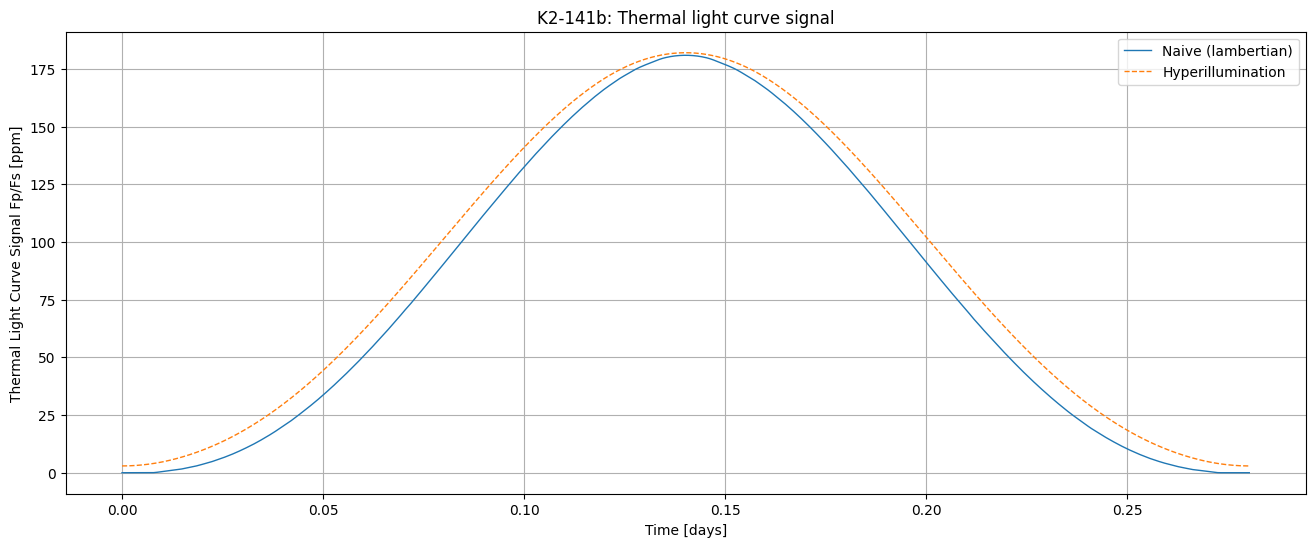

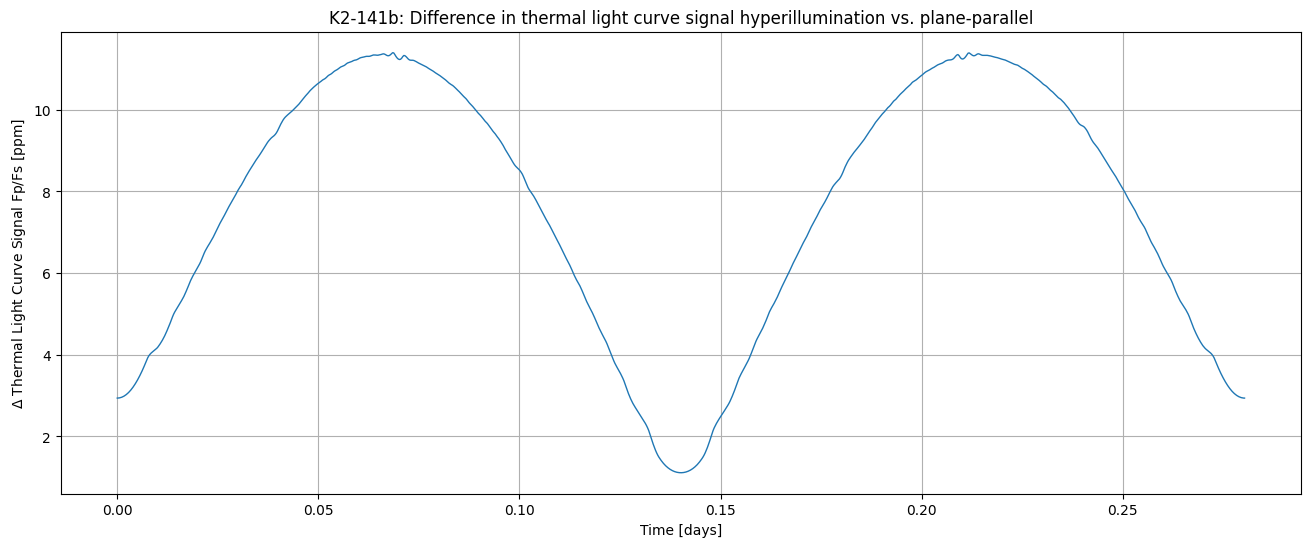

In [11]:
t_kopal, thermal_lightcurve_kopal, _ = hipc.thermal_LightCurve(period, incl, ecc, w, rp, 1, a, T_eff, rs, lambda_range, u=u, insolation_model="kopal")
t_naive, thermal_lightcurve_naive, _ = hipc.thermal_LightCurve(period, incl, ecc, w, rp, 1, a, T_eff, rs, lambda_range, u=u, insolation_model="naive")

plt.figure(figsize=(16, 6))
plt.plot(t_naive, thermal_lightcurve_naive*1e6, linewidth=1, label="Naive (lambertian)")
plt.plot(t_kopal, thermal_lightcurve_kopal*1e6, linewidth=1, linestyle="--", label="Hyperillumination")

plt.xlabel("Time [days]")
plt.ylabel(r"Thermal Light Curve Signal Fp/Fs [ppm]")
plt.title("K2-141b: Thermal light curve signal")
plt.legend()
#plt.ylim(0., 0.8e-7)
plt.grid()
plt.show()

plt.figure(figsize=(16, 6))
plt.plot(t_naive, (thermal_lightcurve_kopal-thermal_lightcurve_naive)*1e6, linewidth=1)
plt.xlabel("Time [days]")
plt.ylabel(f"$\Delta$ Thermal Light Curve Signal Fp/Fs [ppm]")
plt.title("K2-141b: Difference in thermal light curve signal hyperillumination vs. plane-parallel")
#plt.ylim(0., 0.8e-7)
plt.grid()

Wiggles are a numerical artefact in naive light curve signal caused by truncation at 90° (Spiderman converges well only for smooth integrands). Can be fixed by setting n_layers = 120.

Difference in occultation depth between hyperillumination and plane-parallel (naive) model no good proxi for detectability - negligible phase curve differences at alpha=0...

## Consistency Check: Compare custom Spiderman model `insolation=naive` with Spiderman Louden model `F=0`

SPIDERMAN's "Louden" brightness model implements the Kreidberg & Loeb (2016) toy heat-redistribution map with an added internal-heat term:

$$T(\phi,\lambda) = T_\mathrm{int} + \left[\frac{(1-A_B)\,S}{\sigma}\left((1-2F)\cos\phi\cos\lambda + \tfrac{F}{2}\right)\right]^{1/4},$$

on the dayside ($|\lambda| \leq \pi/2$), and $T = T_\mathrm{int} + \left[(1-A_B)\,S\,F/2\sigma\right]^{1/4}$ on the nightside, where $\phi, \lambda$ are latitude/longitude from the substellar point, $S$ the substellar insolation, and $F \in [0, 0.5]$ the redistribution parameter ($F=0$: instant reradiation, 0 K nightside; $F=0.5$: isothermal planet). It describes a bare, grey, zero-heat-capacity surface in local radiative equilibrium, and is symmetric about the substellar point by construction (no advection, hence no hotspot offset). With $F=0$ and $T_\mathrm{int}=0$ it is analytically identical to the naive plane-parallel map built here from `naive_insolation` + `BBtemp_from_insolation`, and therefore serves as an independent check on the `direct_T` pipeline.

In [12]:
sigma = 5.670374419e-8
insol = sigma * T_eff**4 / (a/1)**2 # a is already in stellar radii -> 5.048e6 W/m^2

sp_louden = sp.ModelParams(brightness_model="Louden", stellar_model="blackbody")
sp_louden.thermal = True
sp_louden.n_layers = 30

sp_louden.t0, sp_louden.per = 0., period
sp_louden.a_abs = a * rs * 6.957e8/1.495978707e11
sp_louden.inc, sp_louden.ecc, sp_louden.w = incl, ecc, w
sp_louden.rp, sp_louden.a = rp, a
sp_louden.p_u1 = sp_louden.p_u2 = 0.

sp_louden.T_s    = T_eff
sp_louden.insol  = insol
sp_louden.albedo = 0.1
sp_louden.redist = 0. # instant reradiation
sp_louden.T_int  = 0.
sp_louden.l1, sp_louden.l2 = lambda_range


t_naive, thermal_lightcurve_naive, _ = hipc.thermal_LightCurve(period, incl, ecc, w, rp, 1, a, T_eff, rs, lambda_range, u=u, insolation_model="naive", exclude_occultation=False)
lightcurve_louden = sp_louden.lightcurve(t_naive)-1

no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation


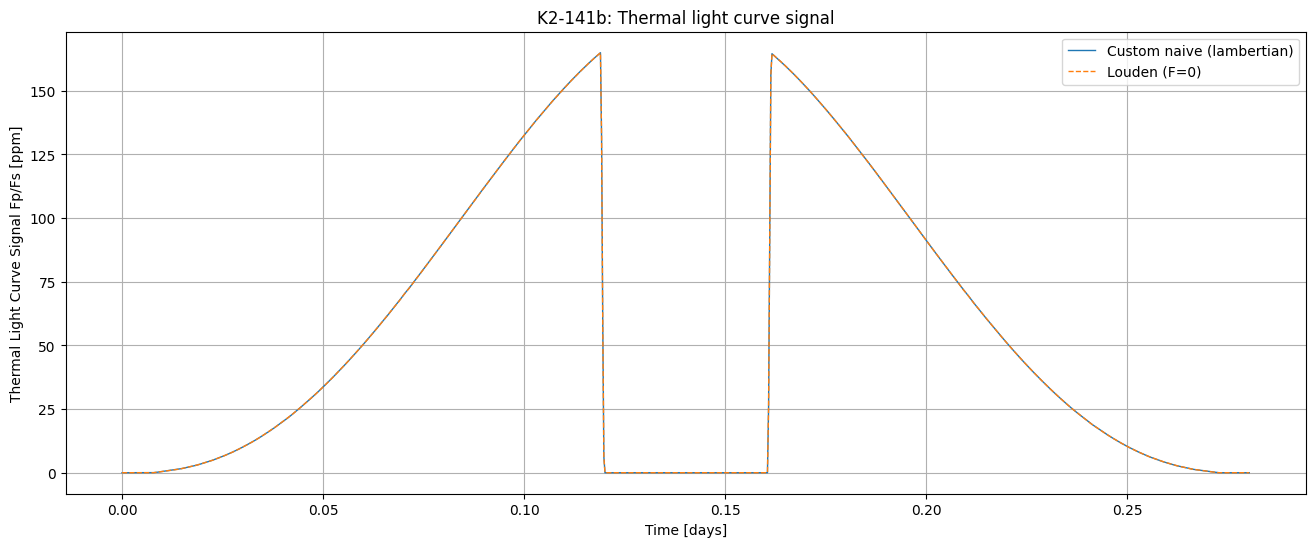

no stellar models provided, using blackbody approximation
Occultation depth Louden (F=0): 180.9 ppm   (measured: fp = 142 ppm at 4.5 um)
Occultation depth custom naive: 180.9 ppm   (measured: fp = 142 ppm at 4.5 um)


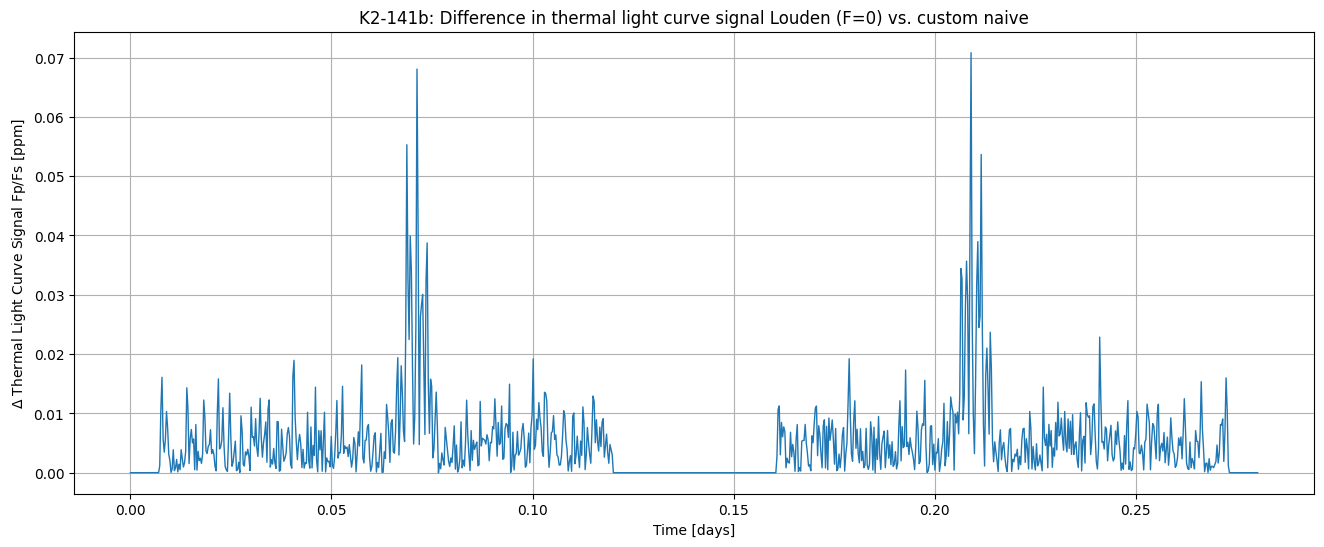

In [13]:
plt.figure(figsize=(16, 6))
plt.plot(t_naive, thermal_lightcurve_naive*1e6, linewidth=1, label="Custom naive (lambertian)")
plt.plot(t_naive, lightcurve_louden*1e6, linewidth=1, linestyle="--", label="Louden (F=0)")
plt.xlabel("Time [days]")
plt.ylabel(r"Thermal Light Curve Signal Fp/Fs [ppm]")
plt.title("K2-141b: Thermal light curve signal")
plt.legend()
#plt.ylim(0., 0.8e-7)
plt.grid()
plt.show()

plt.figure(figsize=(16, 6))
plt.plot(t_naive, np.abs((lightcurve_louden-thermal_lightcurve_naive))*1e6, linewidth=1)
plt.xlabel("Time [days]")
plt.ylabel(f"$\Delta$ Thermal Light Curve Signal Fp/Fs [ppm]")
plt.title("K2-141b: Difference in thermal light curve signal Louden (F=0) vs. custom naive")
#plt.ylim(0., 0.8e-7)
plt.grid()

print(f"Occultation depth Louden (F=0): {sp_louden.eclipse_depth()*1e6:.1f} ppm   (measured: fp = {fp*1e6:.0f} ppm at 4.5 um)")
print(f"Occultation depth custom naive: {thermal_fp_naive*1e6:.1f} ppm   (measured: fp = {fp*1e6:.0f} ppm at 4.5 um)")

## Parameter Sweep

#### Sweep 1: Bond albedo $A_B$ (Spitzer/IRAC)

no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation


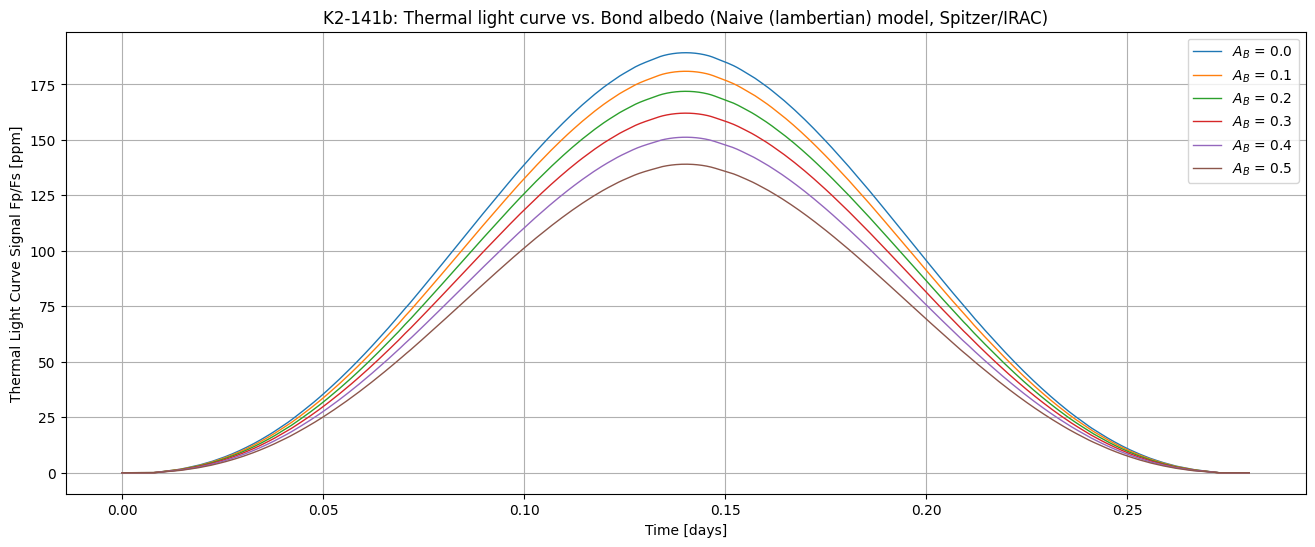

no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation


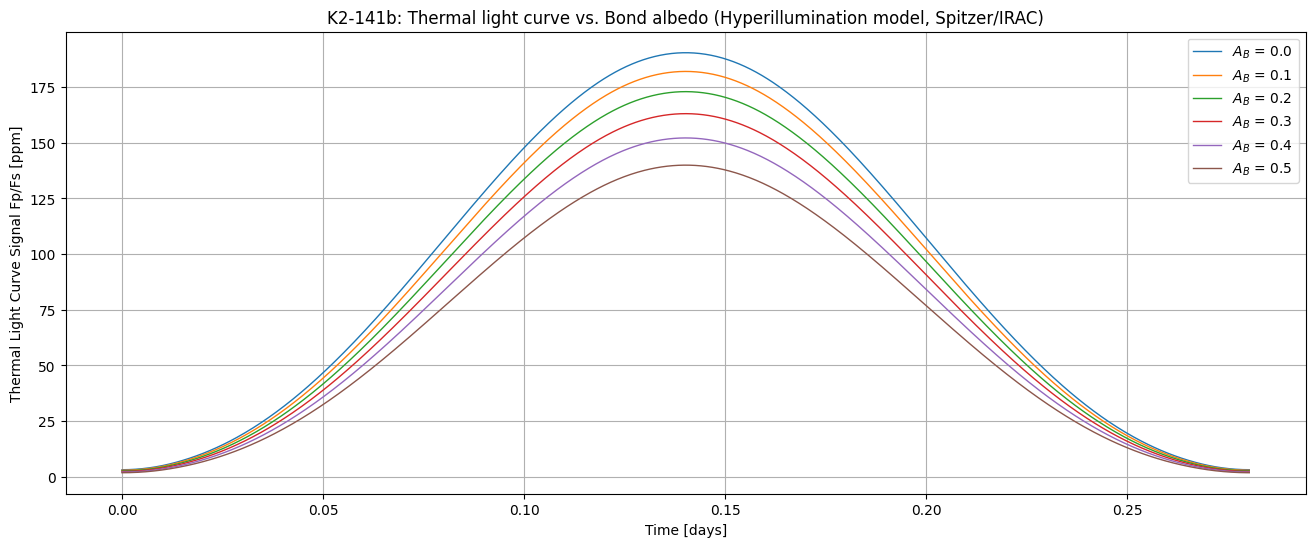

In [14]:
A_B_sweep = np.arange(0.0, 0.51, 0.1)  # 0.0, 0.1, ..., 0.5

for insolation_model, label in [("naive", "Naive (lambertian)"), ("kopal", "Hyperillumination")]:
    plt.figure(figsize=(16, 6))
    for A_B_val in A_B_sweep:
        t_sw, lc_sw, _ = hipc.thermal_LightCurve(period, incl, ecc, w, rp, 1, a, T_eff, rs, lambda_range,
                                                  u=u, insolation_model=insolation_model, A_B=A_B_val)
        plt.plot(t_sw, lc_sw*1e6, linewidth=1, label=f"$A_B$ = {A_B_val:.1f}")
    plt.xlabel("Time [days]")
    plt.ylabel(r"Thermal Light Curve Signal Fp/Fs [ppm]")
    plt.title(f"K2-141b: Thermal light curve vs. Bond albedo ({label} model, Spitzer/IRAC)")
    plt.legend()
    plt.grid()
    plt.show()

#### Sweep 2: Wavelength range ($A_B$ = 0.1)

no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation


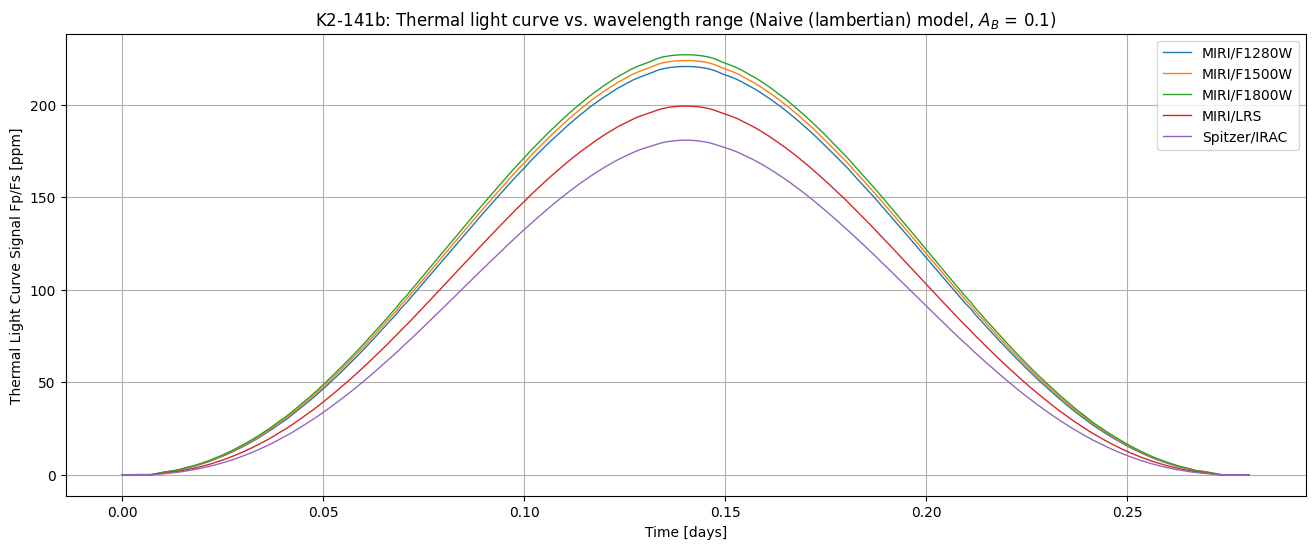

no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation


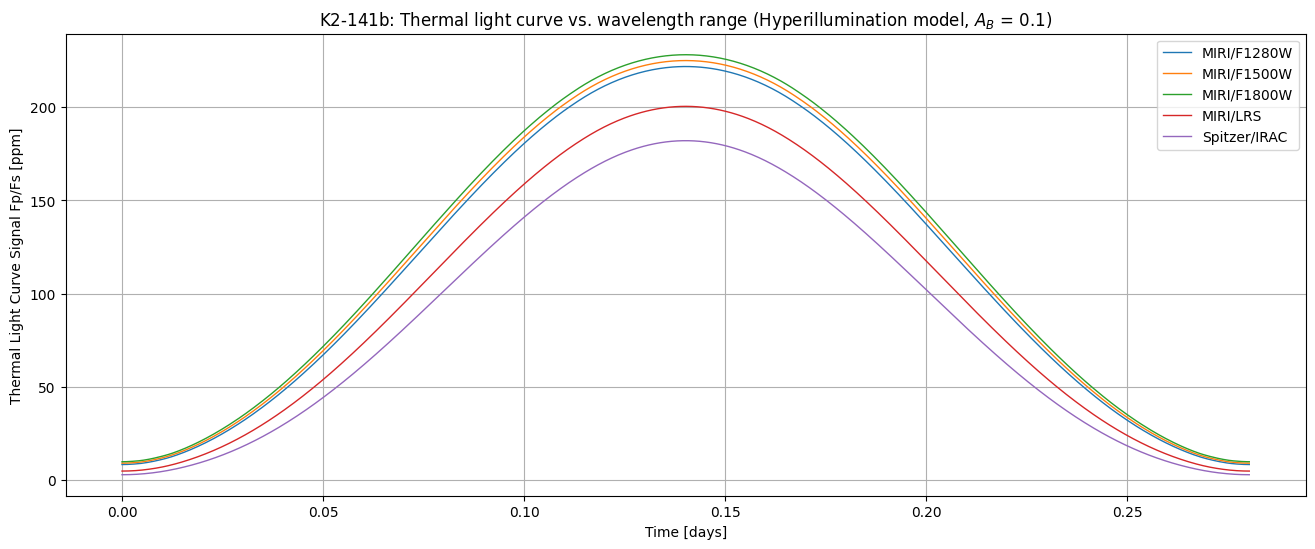

In [15]:
for insolation_model, label in [("naive", "Naive (lambertian)"), ("kopal", "Hyperillumination")]:
    plt.figure(figsize=(16, 6))
    for band_name, band_range in effective_lambda_ranges.items():
        lambda_range_sw = 1e-6*np.array(band_range)
        t_sw, lc_sw, _ = hipc.thermal_LightCurve(period, incl, ecc, w, rp, 1, a, T_eff, rs, lambda_range_sw,
                                                  u=u, insolation_model=insolation_model, A_B=0.1)
        plt.plot(t_sw, lc_sw*1e6, linewidth=1, label=band_name)
    plt.xlabel("Time [days]")
    plt.ylabel(r"Thermal Light Curve Signal Fp/Fs [ppm]")
    plt.title(f"K2-141b: Thermal light curve vs. wavelength range ({label} model, $A_B$ = 0.1)")
    plt.legend()
    plt.grid()
    plt.show()

## Difference between hyperillumination and naive model 

Ceteris paribus sweeps: for each parameter, all other parameters are held at the K2-141b baseline values set at the top of this notebook (`period, incl, ecc, w, rp, a, T_eff, u, A_B, lambda_range`), and only the swept parameter is varied. Each plot shows the Hyperillumination - Naive difference in the thermal light curve signal.

In [16]:
# Baseline kwargs matching hipc.thermal_LightCurve's parameter names (r2=1 is the stellar-radius normalization, R_star=rs in solar radii)
baseline_kwargs = dict(period=period, incl=incl, ecc=ecc, w=w, r1=rp, r2=1, R=a,
                        T2_eff=T_eff, R_star=rs, lambda_range=lambda_range, u=u, A_B=A_B)

def sweep_hyperillumination_minus_naive(param_name, values, label_fmt, title_suffix, **fixed_kwargs):
    plt.figure(figsize=(16, 6))
    for val in values:
        kwargs = dict(fixed_kwargs)
        kwargs[param_name] = val
        t_k, lc_k, _ = hipc.thermal_LightCurve(**kwargs, insolation_model="kopal")
        _,   lc_n, _ = hipc.thermal_LightCurve(**kwargs, insolation_model="naive")
        if param_name=="period": plt.plot(t_k/val, (lc_k - lc_n)*1e6, linewidth=1, label=label_fmt(val))
        else: plt.plot(t_k, (lc_k - lc_n)*1e6, linewidth=1, label=label_fmt(val))
    if param_name=="period": plt.xlabel("Orbital Phase")
    else: plt.xlabel("Time [days]")
    plt.ylabel(r"$\Delta$ Thermal Light Curve Signal Fp/Fs [ppm] (Hyperillumination $-$ Naive)")
    plt.title(f"K2-141b: Hyperillumination $-$ Naive vs. {title_suffix}")
    plt.legend()
    plt.grid()
    plt.show()

#### Bond albedo $A_B$

no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation


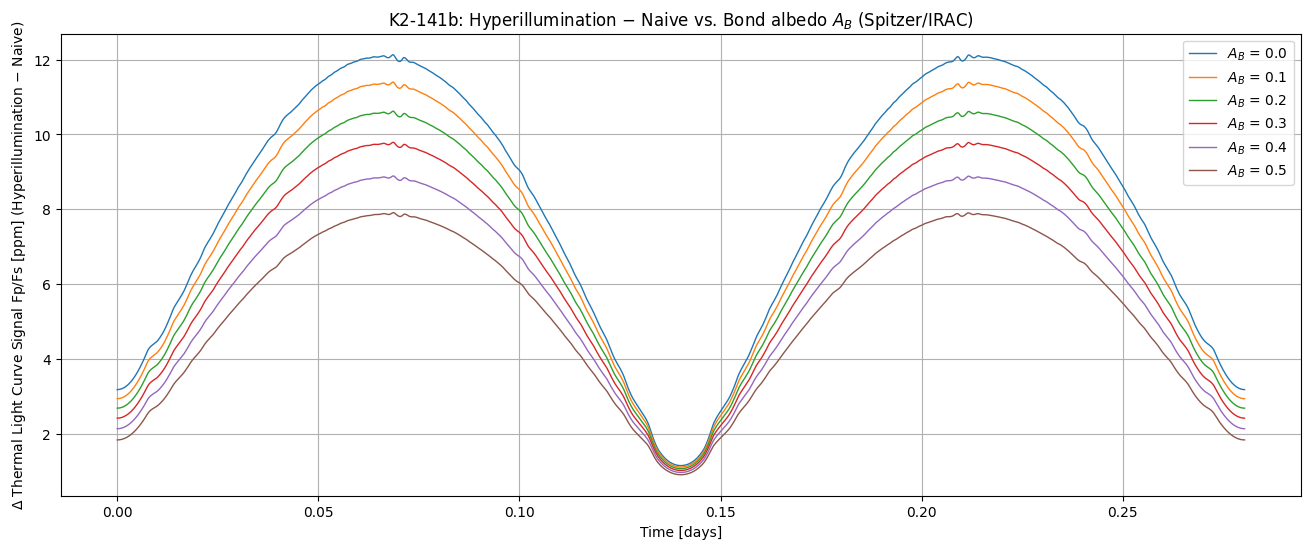

In [17]:
sweep_hyperillumination_minus_naive(
    "A_B", np.arange(0.0, 0.51, 0.1), lambda v: f"$A_B$ = {v:.1f}",
    "Bond albedo $A_B$ (Spitzer/IRAC)", **baseline_kwargs)

#### Wavelength range

no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation


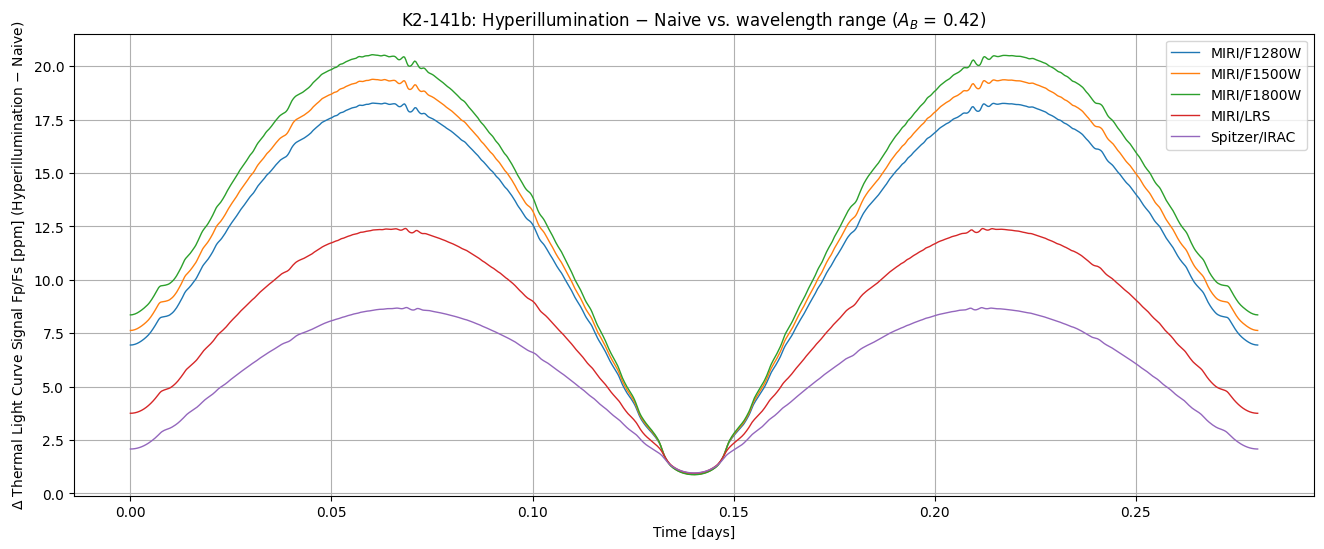

In [18]:
# lambda_range values are (start, end) pairs, not scalars -> special-cased instead of using the generic helper
plt.figure(figsize=(16, 6))
for band_name, band_range in effective_lambda_ranges.items():
    kwargs = dict(baseline_kwargs)
    kwargs["lambda_range"] = 1e-6*np.array(band_range)
    t_k, lc_k, _ = hipc.thermal_LightCurve(**kwargs, insolation_model="kopal")
    _,   lc_n, _ = hipc.thermal_LightCurve(**kwargs, insolation_model="naive")
    plt.plot(t_k, (lc_k - lc_n)*1e6, linewidth=1, label=band_name)
plt.xlabel("Time [days]")
plt.ylabel(r"$\Delta$ Thermal Light Curve Signal Fp/Fs [ppm] (Hyperillumination $-$ Naive)")
plt.title(f"K2-141b: Hyperillumination $-$ Naive vs. wavelength range ($A_B$ = {A_B:.2f})")
plt.legend()
plt.grid()
plt.show()

#### Stellar limb darkening $u$

no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation


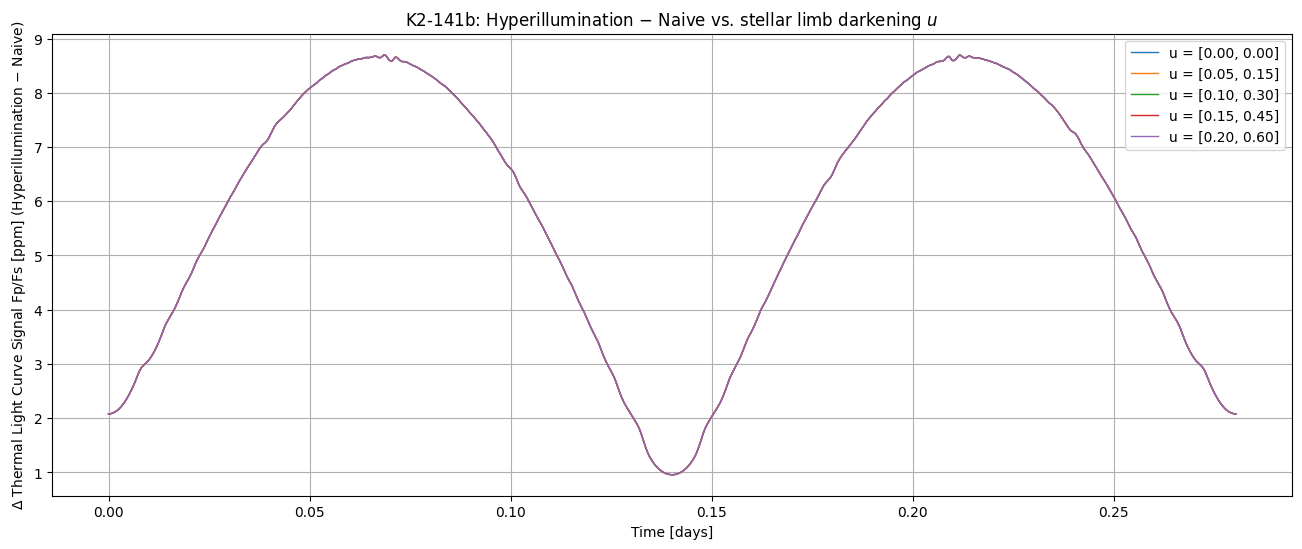

In [19]:
# TODO only limb darkening effect is in hyperillumination insolation model - to be modified to quadratic
u_factors = np.array([0.0, 0.5, 1.0, 1.5, 2.0])  # scaling the K2-141b placeholder u = [0.1, 0.3]
sweep_hyperillumination_minus_naive(
    "u", [list(f*np.array(u)) for f in u_factors],
    lambda v: f"u = [{v[0]:.2f}, {v[1]:.2f}]",
    "stellar limb darkening $u$", **baseline_kwargs)

#### Stellar effective temperature $T_\mathrm{eff}$

no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation


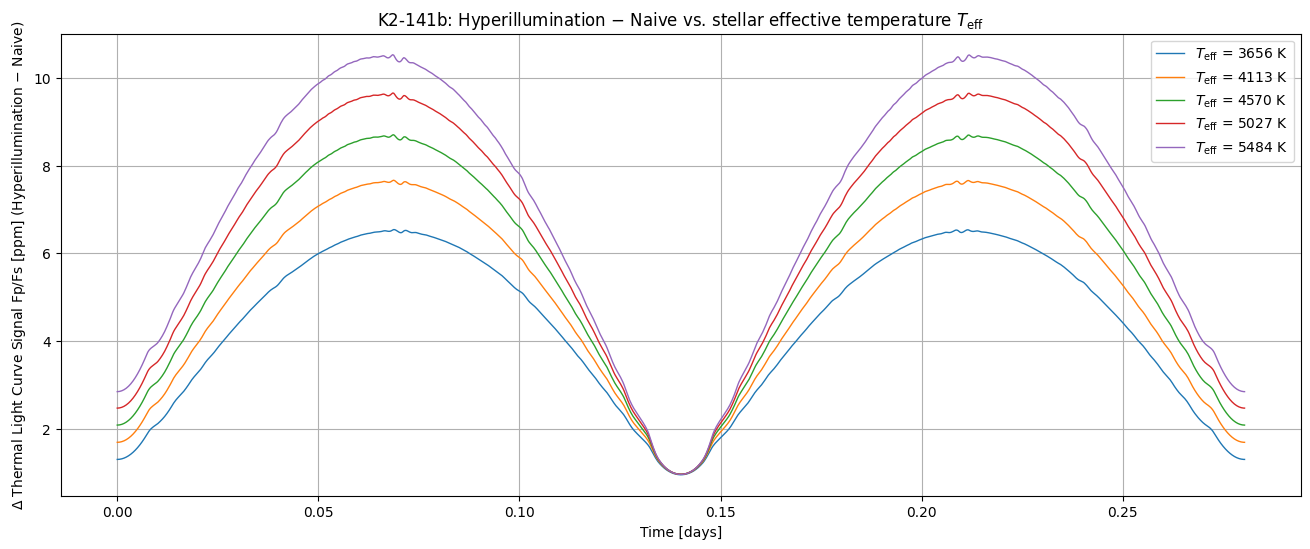

In [20]:
factors = np.array([0.8, 0.9, 1.0, 1.1, 1.2])  # +/- 20% around each K2-141b baseline value

sweep_hyperillumination_minus_naive(
    "T2_eff", T_eff*factors, lambda v: f"$T_\\mathrm{{eff}}$ = {v:.0f} K",
    "stellar effective temperature $T_\\mathrm{eff}$", **baseline_kwargs)

#### Planet radius / Stellar radius $r_p$

no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation


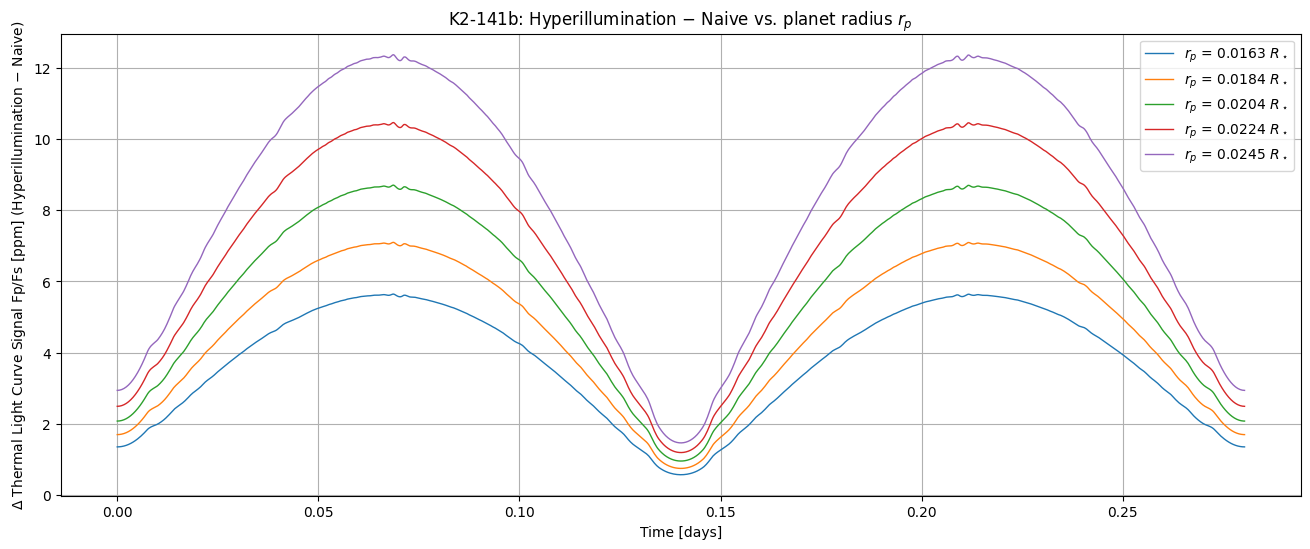

In [21]:
sweep_hyperillumination_minus_naive(
    "r1", rp*factors, lambda v: f"$r_p$ = {v:.4f} $R_\\star$",
    "planet radius $r_p$", **baseline_kwargs)

#### Semi-major axis / Stellar radius $a$

no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation


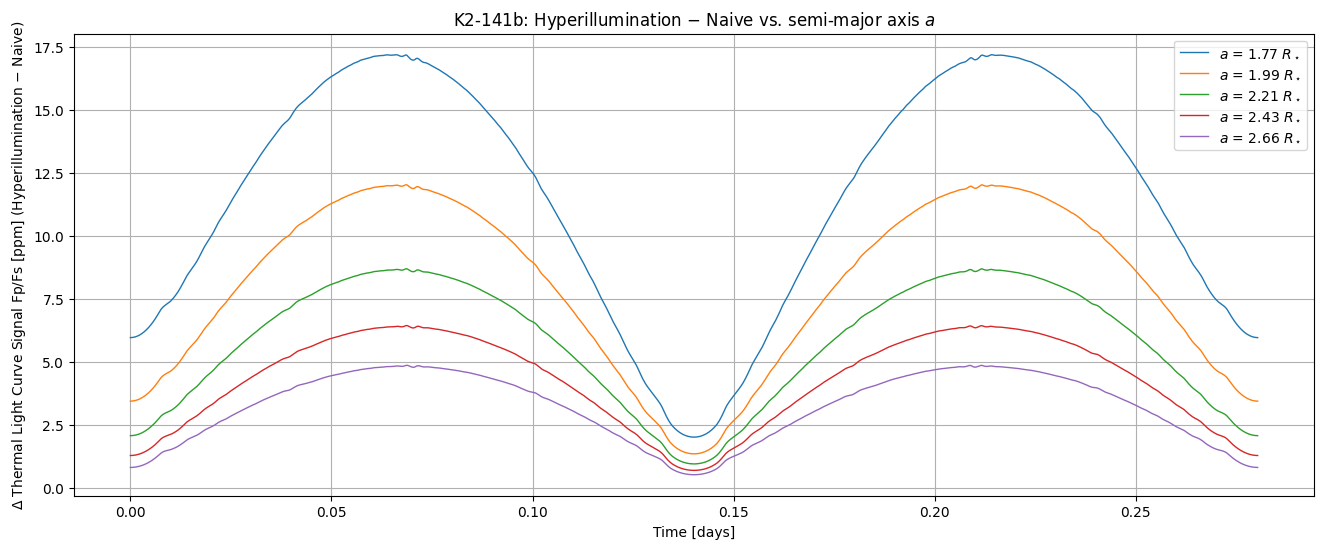

In [22]:
sweep_hyperillumination_minus_naive(
    "R", a*factors, lambda v: f"$a$ = {v:.2f} $R_\\star$",
    "semi-major axis $a$", **baseline_kwargs)

#### Orbital period

no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation
no stellar models provided, using blackbody approximation


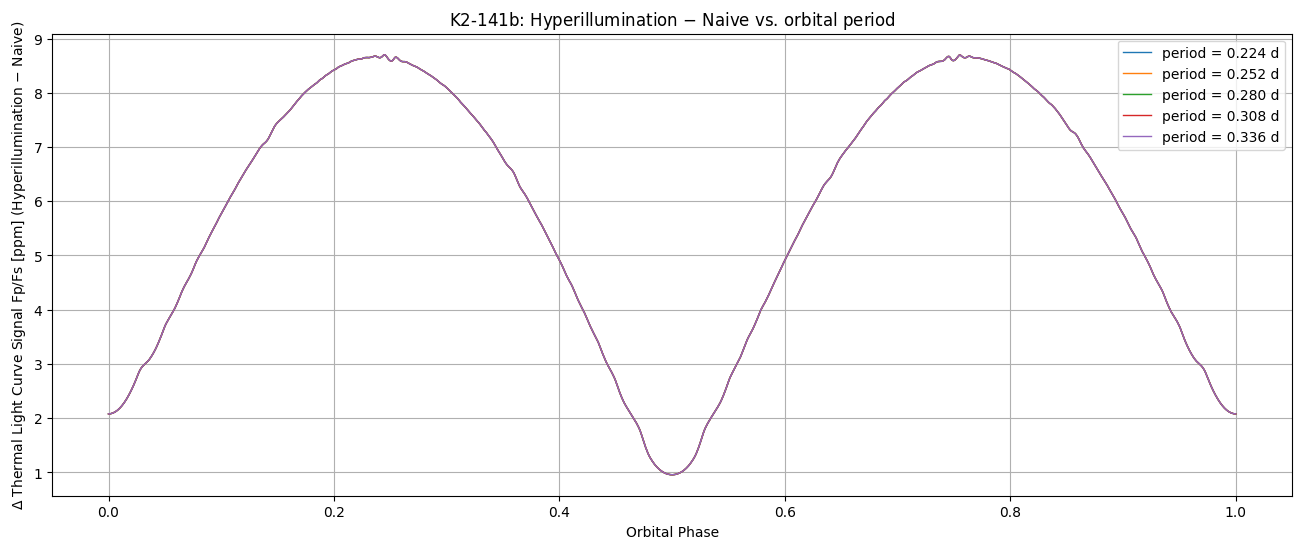

In [23]:
# NOTE: varying the period also changes each curve's total time span (t = linspace(0, period, 1000) internally)
sweep_hyperillumination_minus_naive(
    "period", period*factors, lambda v: f"period = {v:.3f} d",
    "orbital period", **baseline_kwargs)